## Initial Data Load

In [1]:
pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
# Load the dataset
raw_df = pd.read_csv("./dataset/WOD_1931-2025.csv")

## Initial Data Understanding

In [5]:
raw_df.sample(5)

,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,DSRNoon,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO
2140,WOD2141,FENZ,A074919,1687557.0,6103011.0,-35.212105,173.961985,31,10,1999,...,3.010463,0.0,0.0,0.0,0.0,30.0,31.0,33.0,9.1,Neutral
22301,WOD22302,FENZ,F0406710,1744587.0,5931086.0,-36.754969,174.619765,17,4,2009,...,1.786656,0.1,0.1,0.1,0.1,7.0,8.0,9.0,8.6,Neutral
27103,WOD27104,FENZ,F0644399,1928985.0,5611697.0,-39.581330,176.830268,24,3,2010,...,4.352326,0.0,0.0,0.0,0.0,7.0,11.0,18.0,-10.6,Neutral
111609,WOD81450,FENZ,F3271825,1736183.0,6043519.0,-35.742922,174.506073,25,6,2021,...,0.002847,0.2,0.2,0.2,0.2,3.0,4.0,5.0,2.6,Neutral
7189,WOD7190,FENZ,A335208,1718594.0,6049312.0,-35.692981,174.310747,6,11,2002,...,0.115792,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-6.0,El Nino


In [6]:
raw_df.columns

Index(['ID', 'Source', 'OrgID', 'X', 'Y', 'Lat', 'Lon', 'Day', 'Month', 'Year',
       ...
       'DSRNoon', 'PrecipNoon', 'Precip24hr', 'Precip48hr', 'Precip72hr',
       'NoRain1', 'NoRain2', 'NoRain3', 'SOI', 'ENSO'],
      dtype='object', length=109)

In [7]:
df = raw_df.copy()

In [8]:
df.sample(5)

,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,DSRNoon,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO
66451,WOD34892,FENZ,F1054205,1312101.0,4951117.0,-45.533940,169.312717,10,10,2011,...,4.844948,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,7.3,La Nina
79967,WOD49694,FENZ,F1712795,1549101.0,5144361.0,-43.852082,172.366716,23,10,2014,...,2.689574,0.0,0.0,0.0,1.6,2.0,4.0,13.0,-8.0,El Nino
91205,WOD61296,FENZ,F2224514,1767916.0,5898926.0,-37.040877,174.888121,12,1,2017,...,1.771111,0.2,0.2,0.4,0.4,9.0,10.0,15.0,1.3,Neutral
90707,WOD60793,FENZ,F2213050,2023408.0,5671449.0,-39.003519,177.888704,22,12,2016,...,12.943417,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,2.6,Neutral
94699,WOD64981,FENZ,F2440694,1778975.0,5574520.0,-39.960540,175.095427,15,12,2017,...,5.972417,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-1.4,Neutral


In [9]:
pd.set_option("display.float_format", "{:4f}".format)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128020 entries, 0 to 128019
Columns: 109 entries, ID to ENSO
dtypes: float64(78), int64(6), object(25)
memory usage: 106.5+ MB


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.replace([-9999, "-9999"], np.nan, inplace=True)

## Exploratory Data Analysis

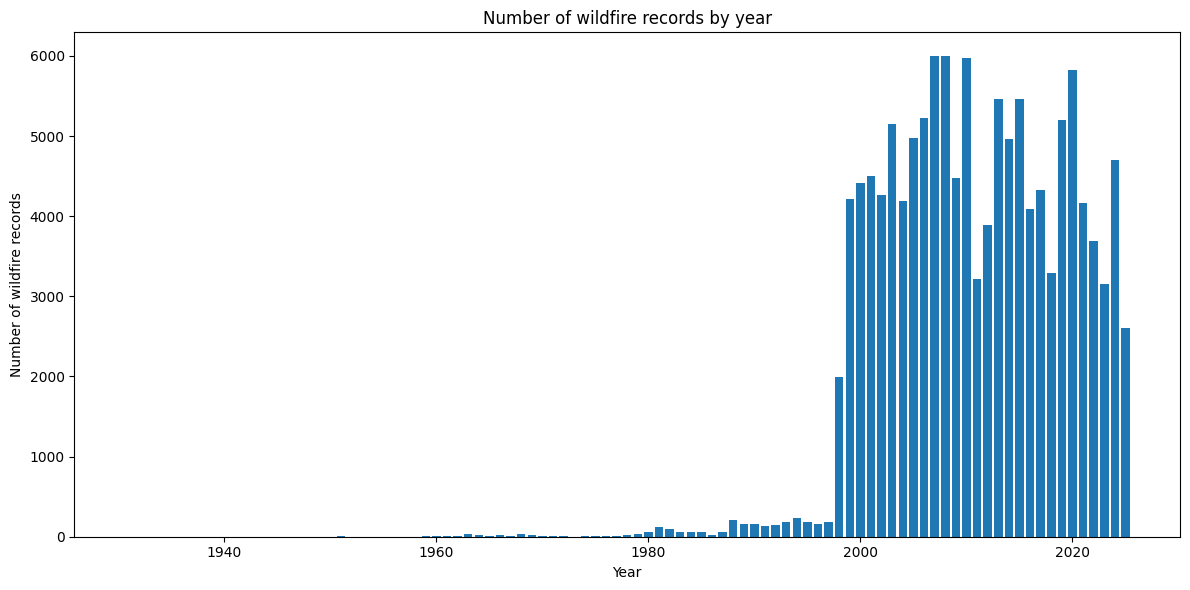

In [12]:
year_counts = df["Year"].value_counts().sort_index()

# Plot
plt.figure(figsize=(12, 6))
plt.bar(year_counts.index, year_counts.values)

plt.xlabel("Year")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records by year")

plt.tight_layout()
plt.show()

<BarContainer object of 28 artists>

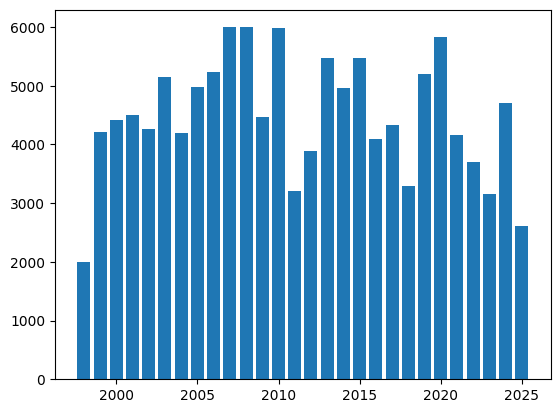

In [13]:
year_counts = df[(df["Year"]>=1998)]["Year"].value_counts().sort_index()
plt.bar(year_counts.index, year_counts.values)

In [14]:
df = df[df["Year"] >= 1998]

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 125407 entries, 0 to 128019
Columns: 109 entries, ID to ENSO
dtypes: float64(79), int64(5), object(25)
memory usage: 105.2+ MB


In [16]:
df.describe()

,X,Y,Lat,Lon,Day,Month,Year,Hour,Minute,StartFY,...,BUINoon,DSRNoon,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI
count,125407.000000,125407.000000,125407.000000,125407.000000,125407.000000,125407.000000,125407.000000,122538.000000,122538.000000,125407.000000,...,114759.000000,121238.000000,95062.000000,85638.000000,80769.000000,76254.000000,94104.000000,93799.000000,93526.000000,125364.000000
mean,1691936.944299,5563542.919748,-40.053201,173.953574,15.313802,6.284266,2011.326369,14.369624,29.469054,2010.793744,...,31.431184,2.733765,0.973404,0.852114,2.186219,3.894114,12.475920,16.214555,19.882642,2.079311
std,178897.754096,356079.179275,3.203534,4.613357,8.950982,4.027923,7.620392,5.218989,17.312773,7.596639,...,28.186253,5.600853,4.074577,3.888488,6.849852,9.872491,19.415931,19.507567,19.627248,10.061453
min,1099987.000122,4756601.760071,-47.211129,-176.609619,1.000000,1.000000,1998.000000,0.000000,0.000000,1997.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-28.600000
25%,1572483.000000,5200570.500000,-43.346221,172.659650,7.000000,2.000000,2005.000000,12.000000,14.000000,2005.000000,...,10.685645,0.125050,0.000000,0.000000,0.000000,0.000000,2.000000,4.000000,7.000000,-5.500000
50%,1750145.000000,5611431.000000,-39.594411,174.698702,15.000000,5.000000,2011.000000,15.000000,29.000000,2010.000000,...,23.399604,0.883178,0.000000,0.000000,0.000000,0.300000,4.000000,8.000000,12.000000,1.300000
75%,1801537.000000,5894228.000000,-37.081245,175.308329,23.000000,11.000000,2018.000000,18.000000,44.000000,2017.000000,...,43.705937,2.965836,0.200000,0.200000,1.200000,3.400000,10.000000,17.000000,23.000000,9.400000
max,2454071.281494,6219769.000000,-34.159987,178.971857,31.000000,12.000000,2025.000000,23.000000,59.000000,2024.000000,...,246.500395,147.704722,208.400000,194.400000,302.000000,326.400000,90.000000,90.000000,90.000000,27.100000


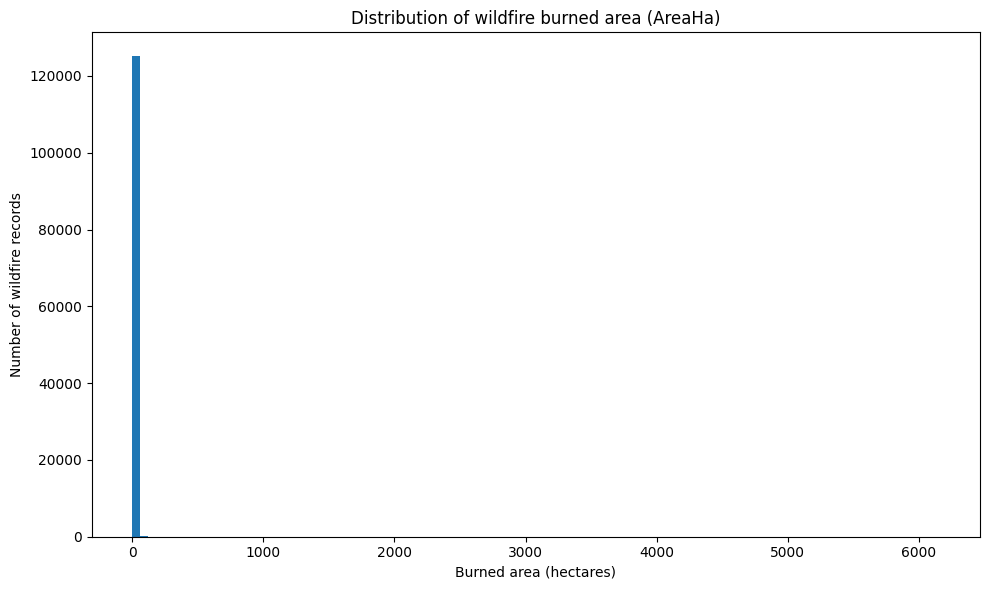

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(df["AreaHa"].dropna(), bins=100)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Distribution of wildfire burned area (AreaHa)")

plt.tight_layout()
plt.show()

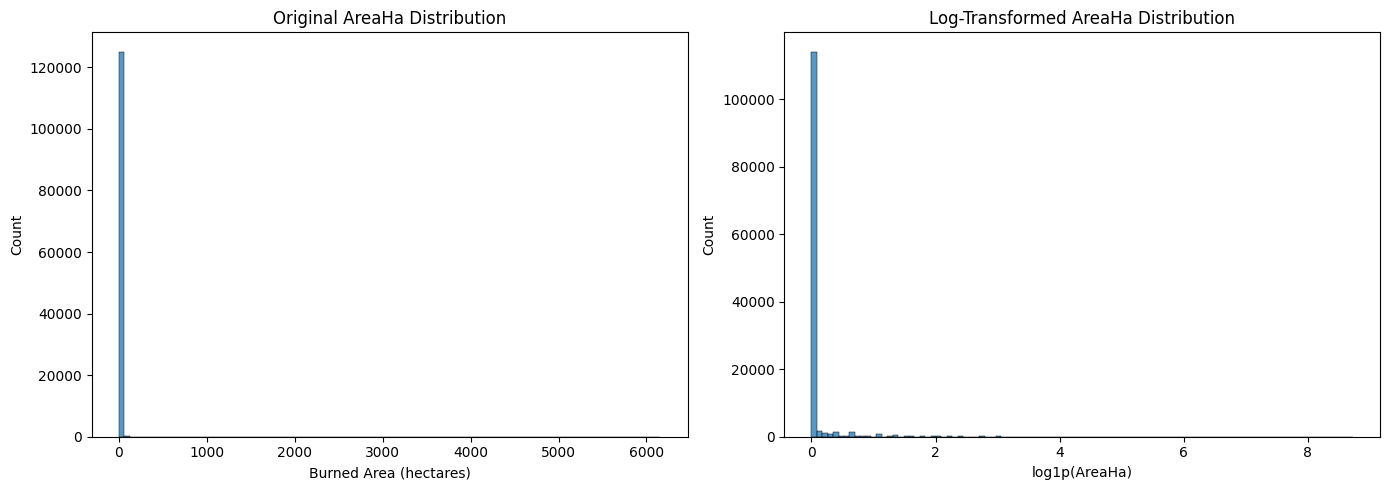

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Log-transform for visualisation only
log_area = np.log1p(df["AreaHa"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["AreaHa"], bins=100, ax=axes[0])
axes[0].set_title("Original AreaHa Distribution")
axes[0].set_xlabel("Burned Area (hectares)")

sns.histplot(log_area, bins=100, ax=axes[1])
axes[1].set_title("Log-Transformed AreaHa Distribution")
axes[1].set_xlabel("log1p(AreaHa)")

plt.tight_layout()
plt.show()

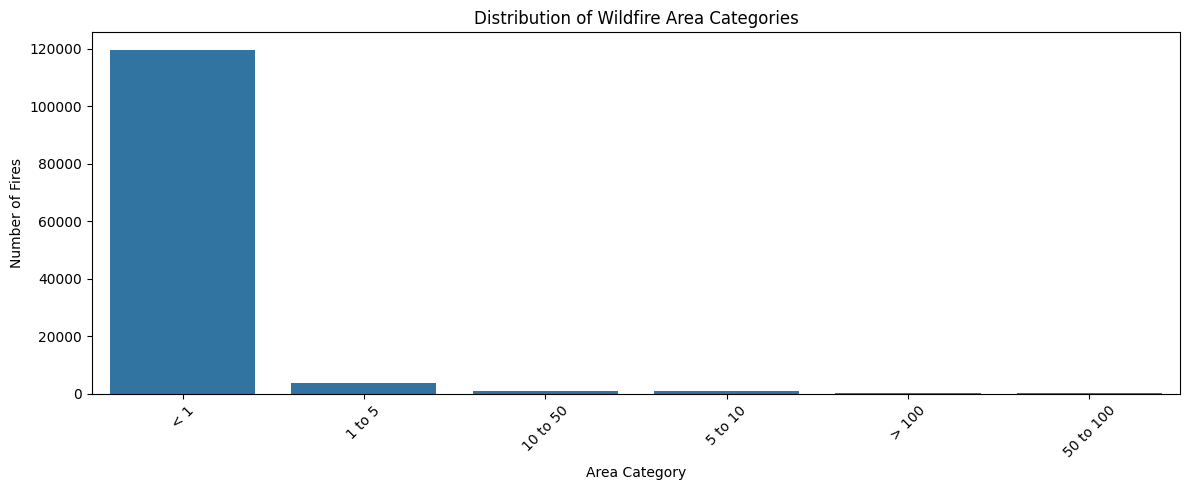

In [19]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="AreaCat",
    order=df["AreaCat"].value_counts().index
)

plt.title("Distribution of Wildfire Area Categories")
plt.xlabel("Area Category")
plt.ylabel("Number of Fires")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
year_category = pd.crosstab(
    df["Year"],
    df["AreaCat"],
    normalize="index"
) * 100

year_category.round(2)

AreaCat,1 to 5,10 to 50,5 to 10,50 to 100,< 1,> 100
Year,,,,,,
1998,1.500000,0.950000,0.750000,0.100000,96.290000,0.400000
1999,1.520000,0.640000,0.310000,0.140000,97.270000,0.120000
2000,2.700000,0.590000,0.390000,0.090000,96.080000,0.160000
2001,6.050000,1.380000,0.710000,0.180000,91.420000,0.270000
2002,4.170000,0.910000,1.060000,0.120000,93.600000,0.140000
2003,3.820000,1.030000,0.910000,0.080000,93.980000,0.170000
2004,3.580000,0.530000,0.430000,0.050000,95.150000,0.260000
2005,3.390000,0.580000,0.680000,0.140000,94.980000,0.220000
2006,3.820000,0.980000,0.650000,0.230000,94.050000,0.270000


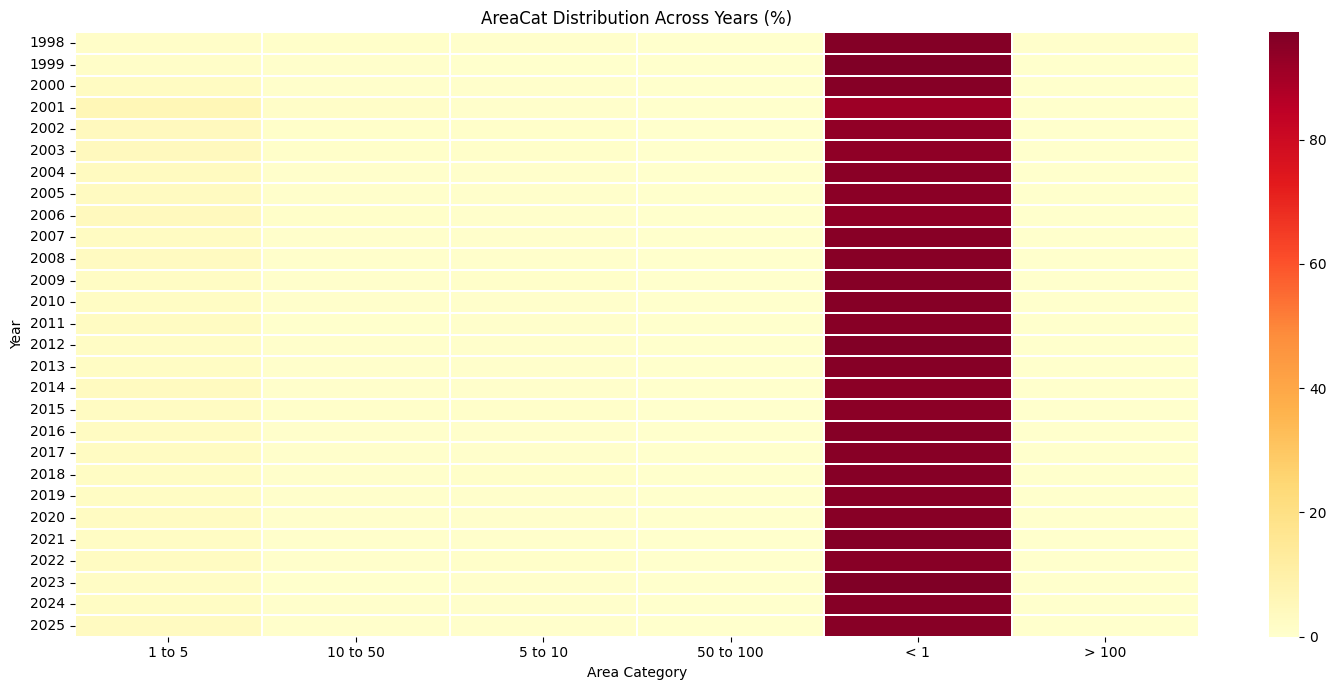

In [21]:
plt.figure(figsize=(15, 7))

sns.heatmap(
    year_category,
    annot=False,
    cmap="YlOrRd",
    linewidths=0.3
)

plt.title("AreaCat Distribution Across Years (%)")
plt.xlabel("Area Category")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

In [22]:
df["Period"] = pd.cut(
    df["Year"],
    bins=[2010, 2015, 2020, 2025],
    labels=["2011-2015", "2016-2020", "2021-2025"]
)

period_distribution = pd.crosstab(
    df["Period"],
    df["AreaCat"],
    normalize="index"
) * 100

period_distribution.round(2)

AreaCat,1 to 5,10 to 50,5 to 10,50 to 100,< 1,> 100
Period,,,,,,
2011-2015,2.870000,0.610000,0.610000,0.140000,95.620000,0.150000
2016-2020,2.780000,0.630000,0.580000,0.150000,95.670000,0.190000
2021-2025,2.590000,0.510000,0.640000,0.070000,96.040000,0.150000


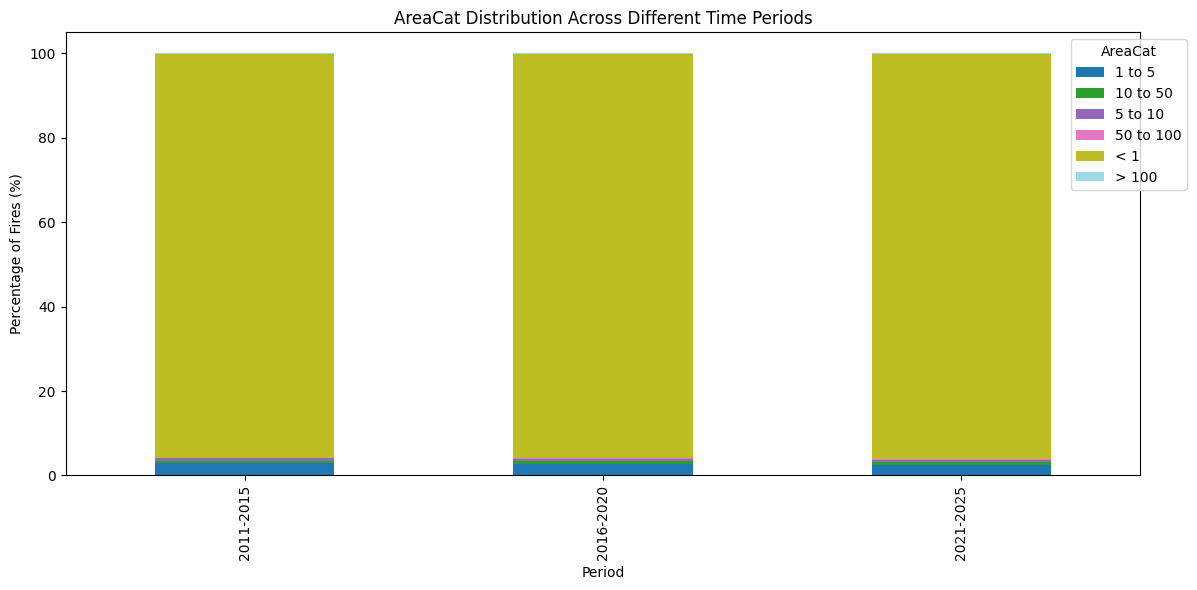

In [23]:
period_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("AreaCat Distribution Across Different Time Periods")
plt.xlabel("Period")
plt.ylabel("Percentage of Fires (%)")
plt.legend(title="AreaCat", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

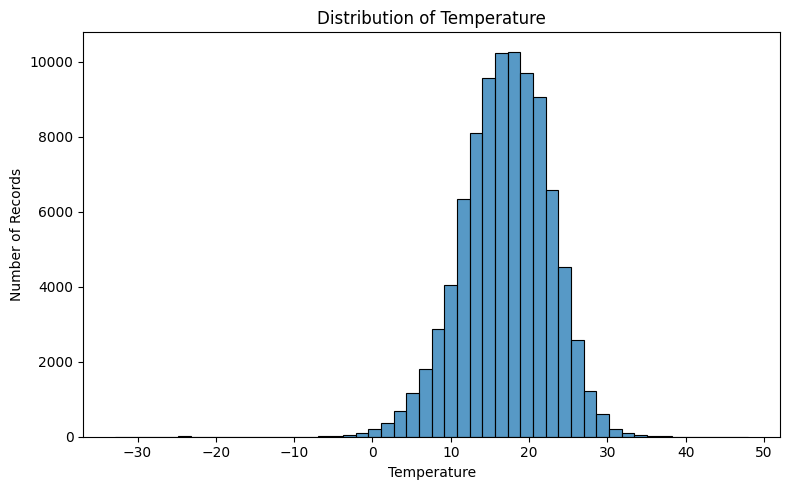

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Temp", bins=50)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

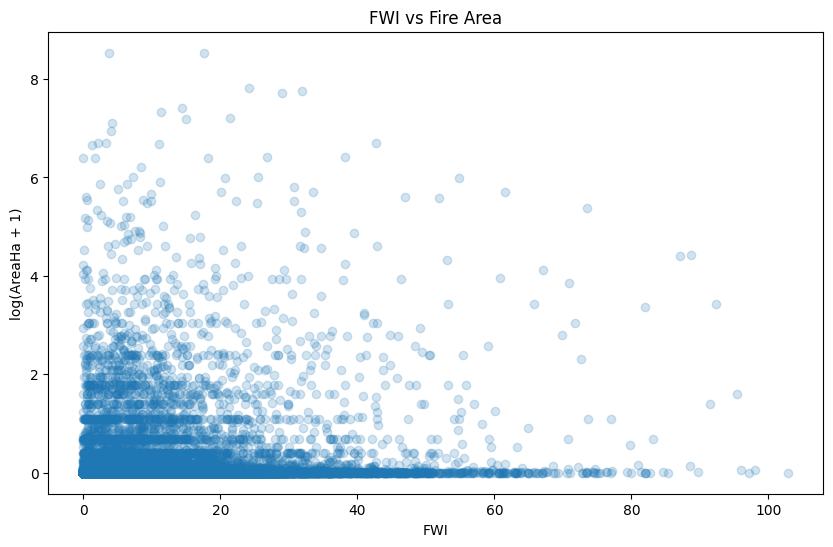

In [25]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["FWI"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("FWI")
plt.ylabel("log(AreaHa + 1)")
plt.title("FWI vs Fire Area")

plt.show()

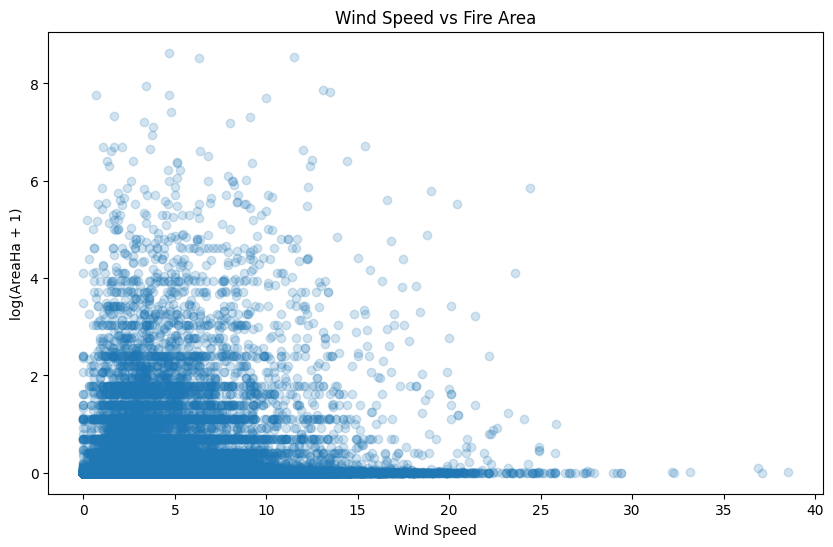

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["WS"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Wind Speed")
plt.ylabel("log(AreaHa + 1)")
plt.title("Wind Speed vs Fire Area")
plt.show()

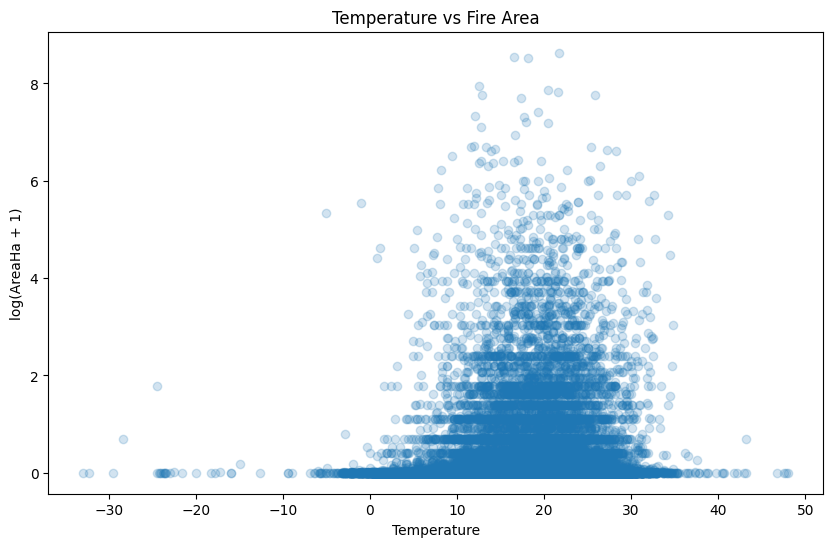

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Temp"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Temperature")
plt.ylabel("log(AreaHa + 1)")
plt.title("Temperature vs Fire Area")
plt.show()

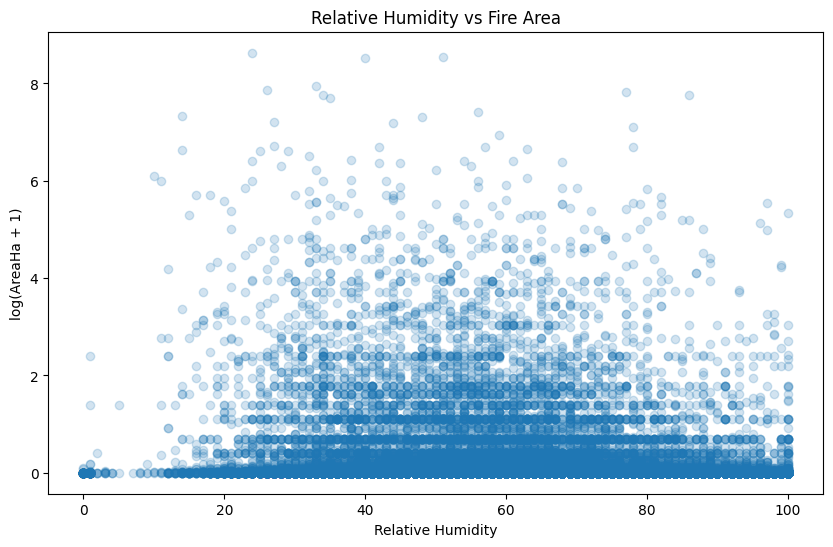

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["RH"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Relative Humidity")
plt.ylabel("log(AreaHa + 1)")
plt.title("Relative Humidity vs Fire Area")
plt.show()

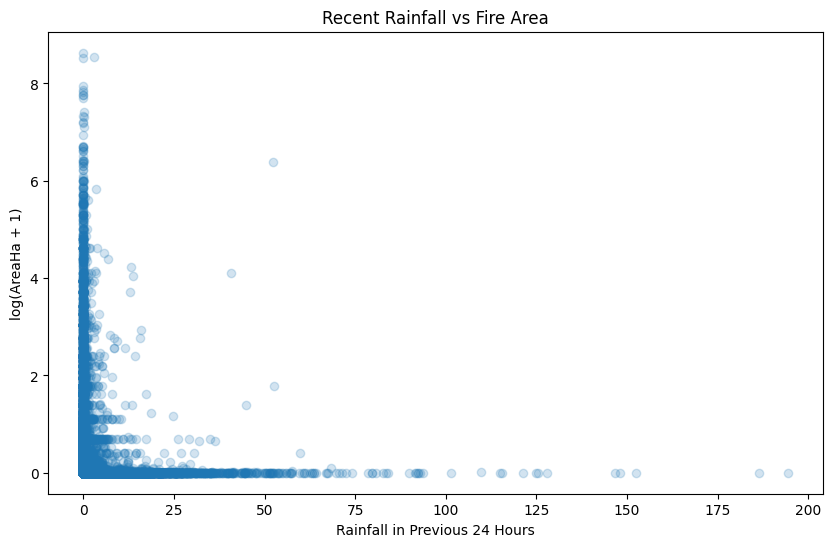

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Precip24hr"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Rainfall in Previous 24 Hours")
plt.ylabel("log(AreaHa + 1)")
plt.title("Recent Rainfall vs Fire Area")
plt.show()

In [30]:
# df[["Precip24hr", "AreaHa"]].skew()


log_df = np.log1p(df[["Precip24hr", "AreaHa"]])

log_df.skew()

Precip24hr   3.031490
AreaHa       7.636004
dtype: float64

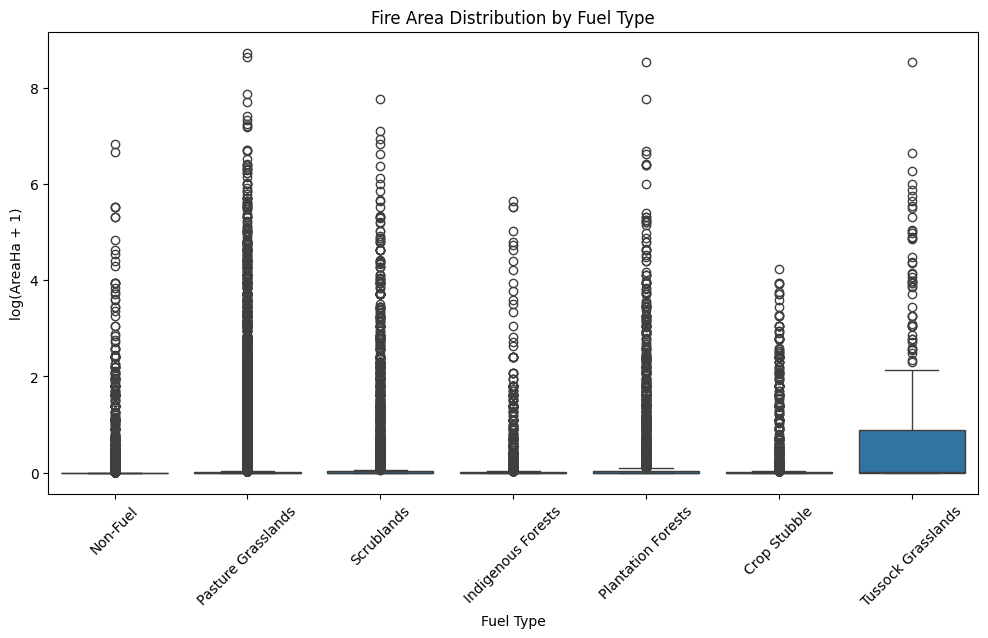

In [31]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="FuelType",
    y=np.log1p(df["AreaHa"])
)

plt.xlabel("Fuel Type")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Fuel Type")
plt.xticks(rotation=45)
plt.show()

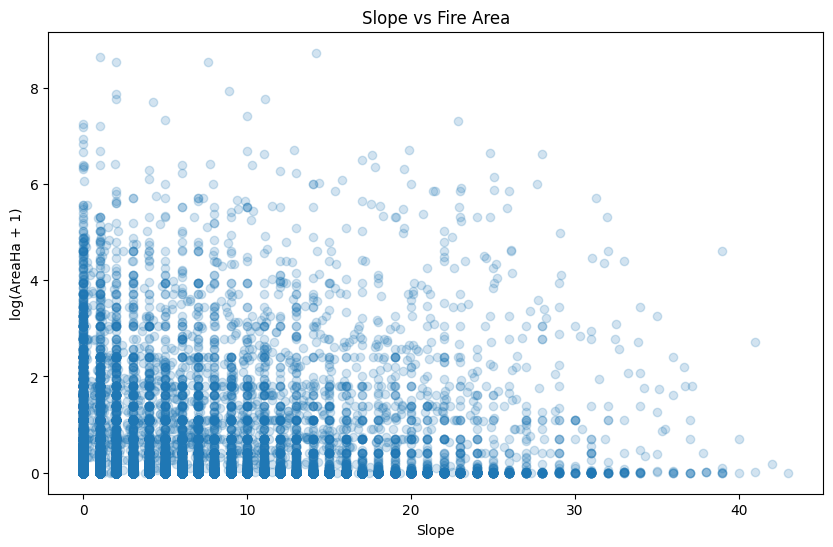

In [32]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Slope"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Slope")
plt.ylabel("log(AreaHa + 1)")
plt.title("Slope vs Fire Area")
plt.show()

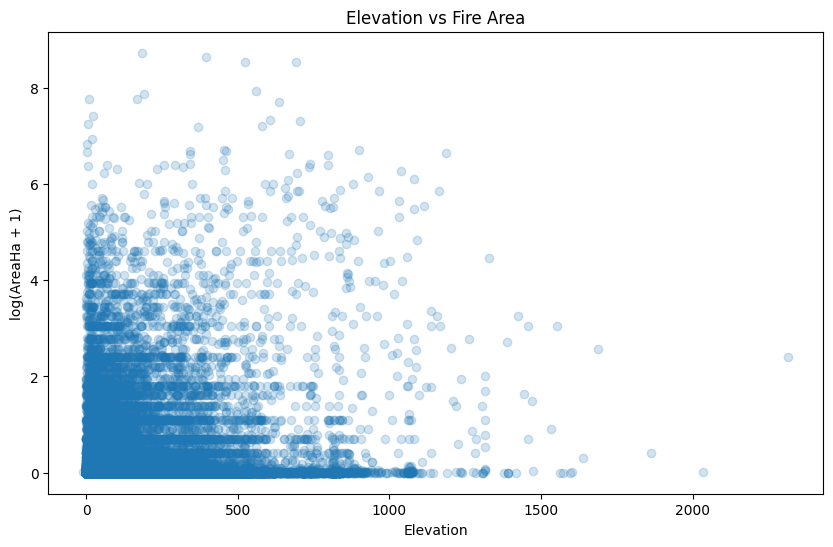

In [33]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Elev"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Elevation")
plt.ylabel("log(AreaHa + 1)")
plt.title("Elevation vs Fire Area")
plt.show()

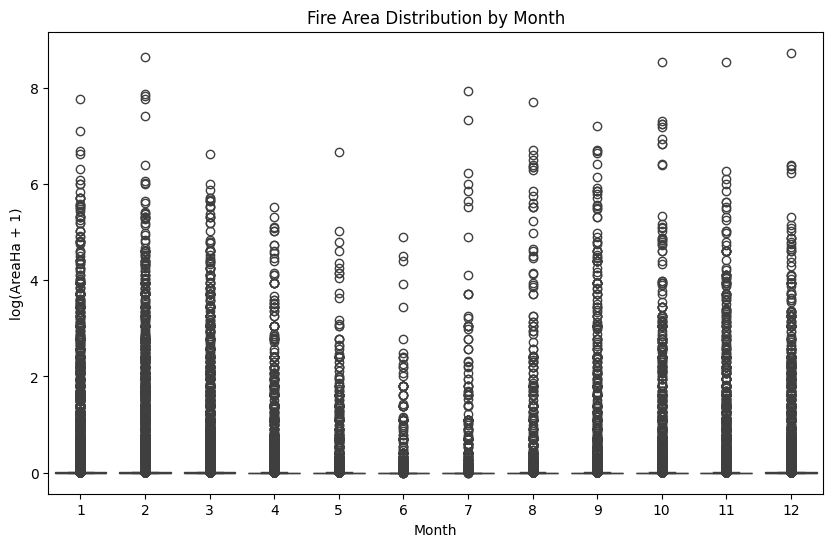

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Month",
    y=np.log1p(df["AreaHa"])
)

plt.xlabel("Month")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Month")
plt.show()

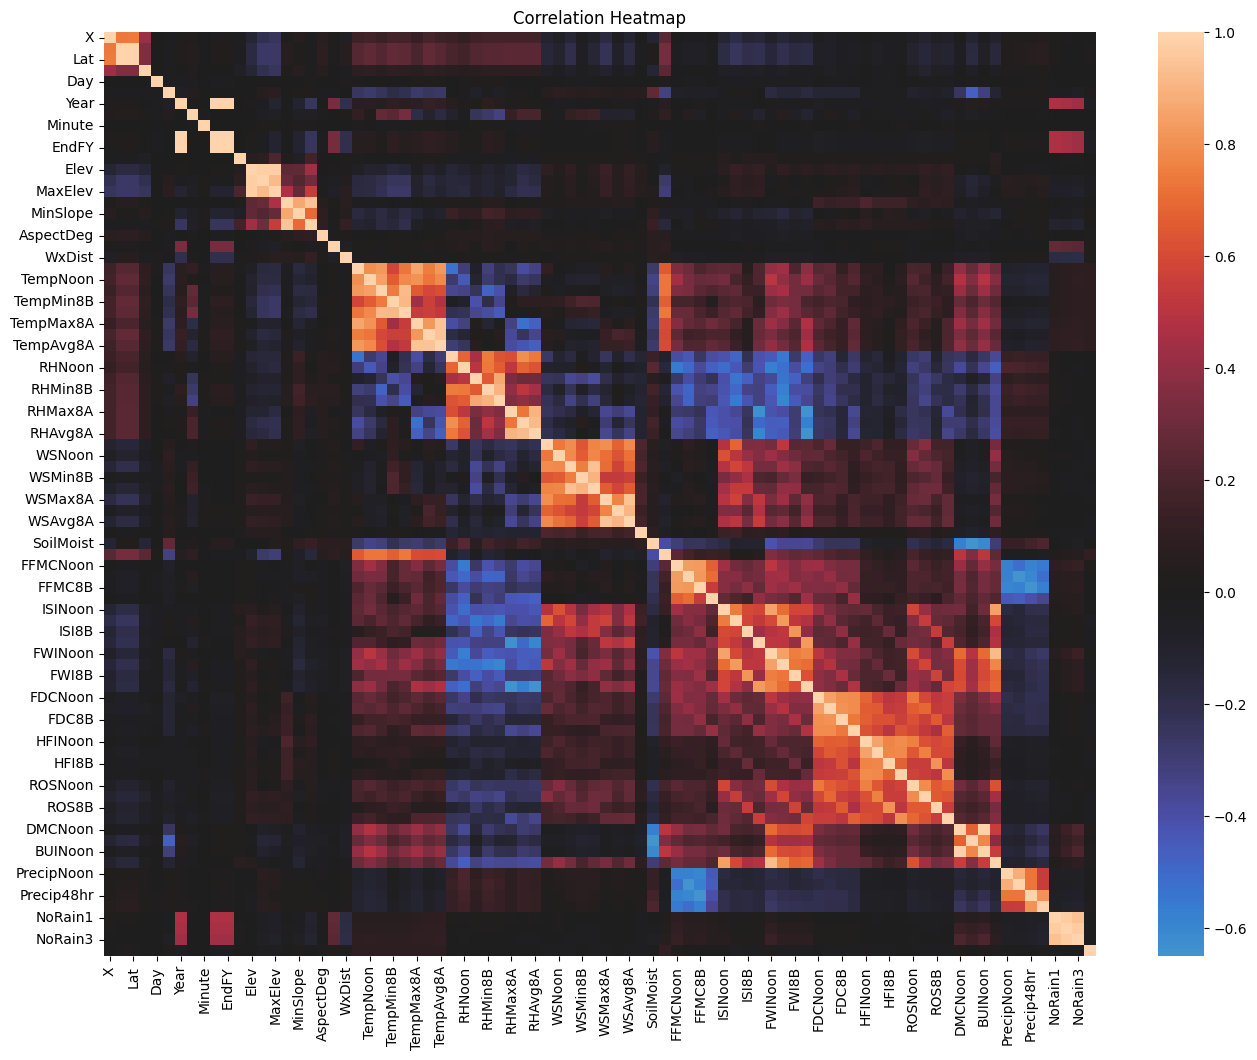

In [35]:
numeric_cols = df.select_dtypes(include="number").columns

plt.figure(figsize=(16, 12))

sns.heatmap(
    df[numeric_cols].corr(),
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

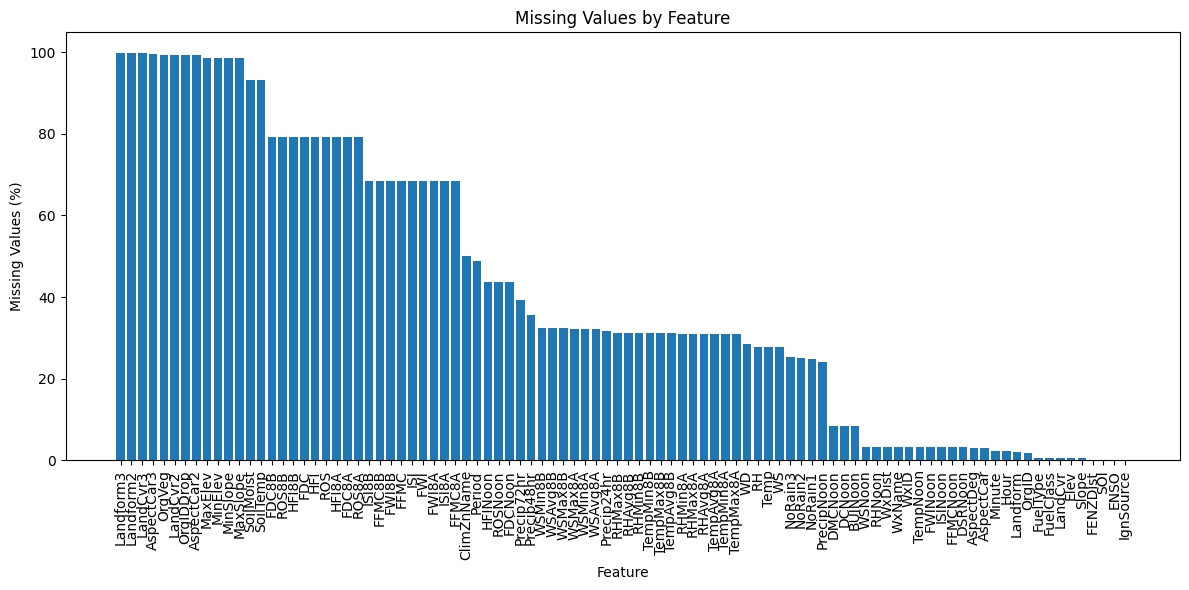

In [36]:
missing = df.isnull().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(12,6))
plt.bar(missing.index, missing.values)

plt.xlabel("Feature")
plt.ylabel("Missing Values (%)")
plt.title("Missing Values by Feature")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

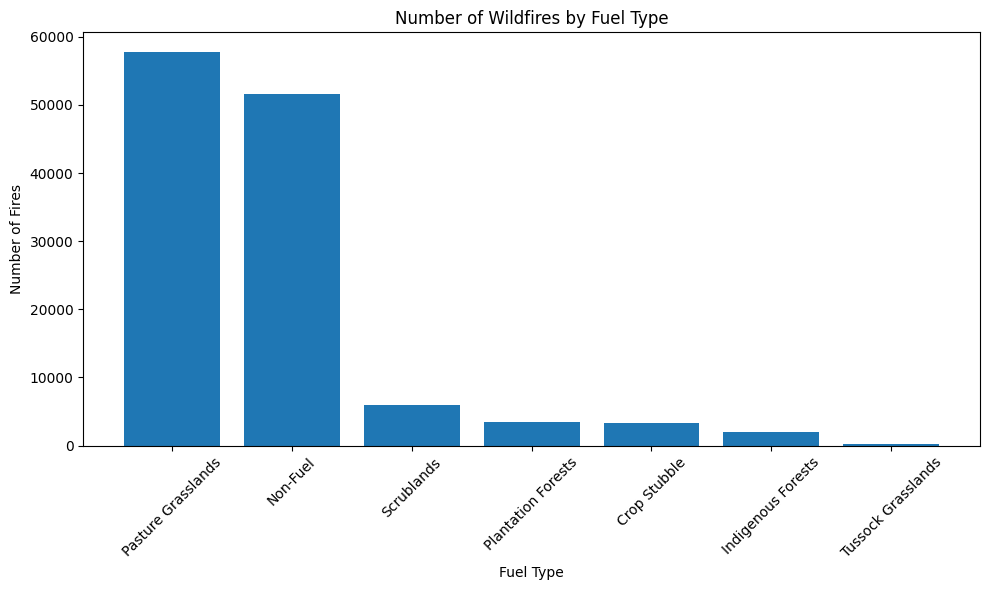

In [37]:
fuel_counts = df["FuelType"].value_counts()

plt.figure(figsize=(10,6))
plt.bar(fuel_counts.index, fuel_counts.values)

plt.xlabel("Fuel Type")
plt.ylabel("Number of Fires")
plt.title("Number of Wildfires by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

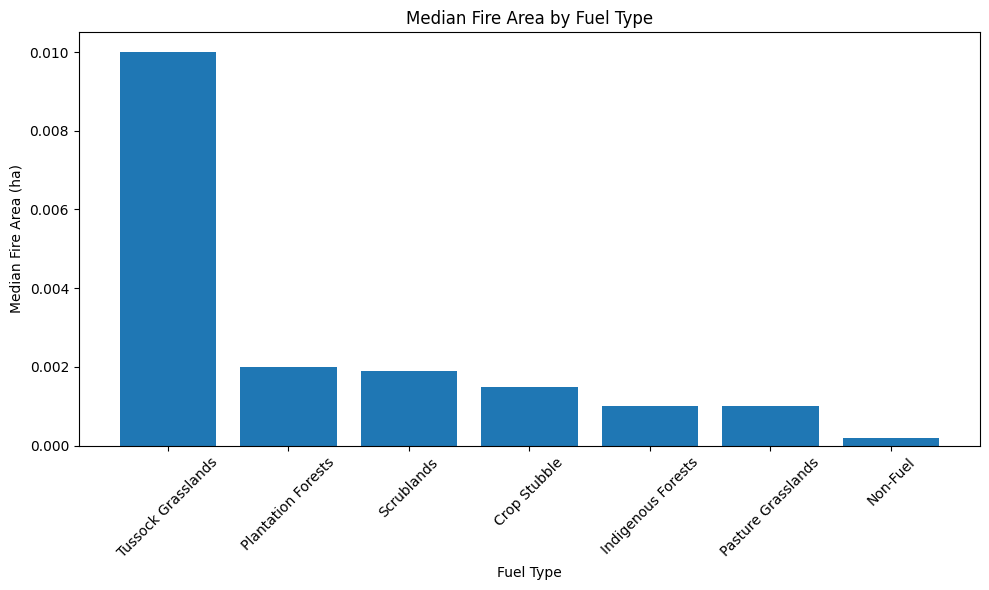

In [38]:
fuel_median = (
    df.groupby("FuelType")["AreaHa"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))
plt.bar(fuel_median.index, fuel_median.values)

plt.xlabel("Fuel Type")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

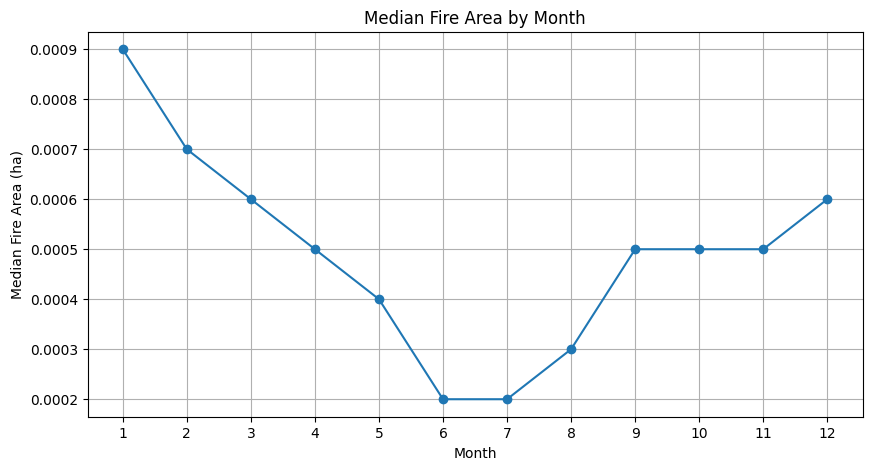

In [39]:
monthly_median = (
    df.groupby("Month")["AreaHa"]
    .median()
)

plt.figure(figsize=(10,5))
plt.plot(
    monthly_median.index,
    monthly_median.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Month")
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

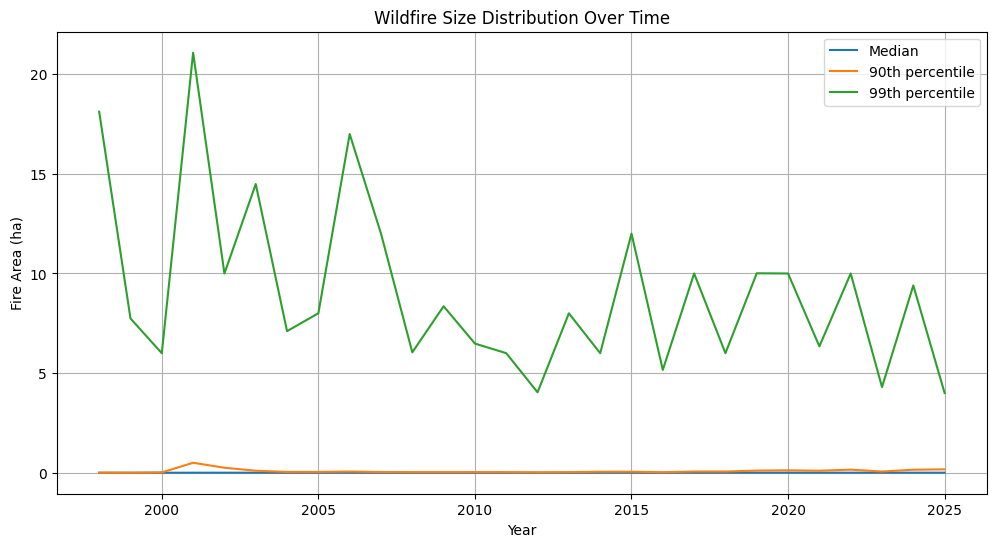

In [40]:
year_area = df.groupby("Year")["AreaHa"].agg(
    median="median",
    p90=lambda x: x.quantile(0.90),
    p99=lambda x: x.quantile(0.99)
)

plt.figure(figsize=(12,6))

plt.plot(year_area.index, year_area["median"], label="Median")
plt.plot(year_area.index, year_area["p90"], label="90th percentile")
plt.plot(year_area.index, year_area["p99"], label="99th percentile")

plt.xlabel("Year")
plt.ylabel("Fire Area (ha)")
plt.title("Wildfire Size Distribution Over Time")
plt.legend()
plt.grid(True)
plt.show()

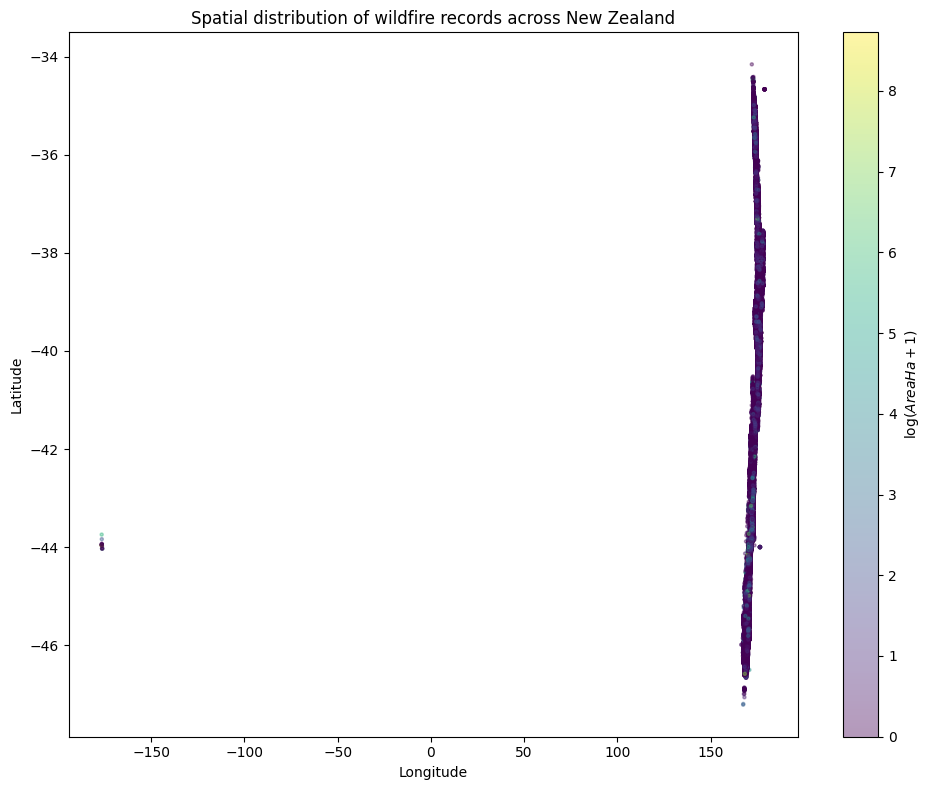

In [41]:
spatial_df = df[
    df["Lon"].notna() &
    df["Lat"].notna() &
    df["AreaHa"].notna()
].copy()

# Log-transform burned area for visualisation
spatial_df["LogArea"] = np.log1p(spatial_df["AreaHa"])

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    spatial_df["Lon"],
    spatial_df["Lat"],
    c=spatial_df["LogArea"],
    s=5,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial distribution of wildfire records across New Zealand")

cbar = plt.colorbar(scatter)
cbar.set_label(r"$\log(AreaHa + 1)$")

plt.tight_layout()
plt.show()

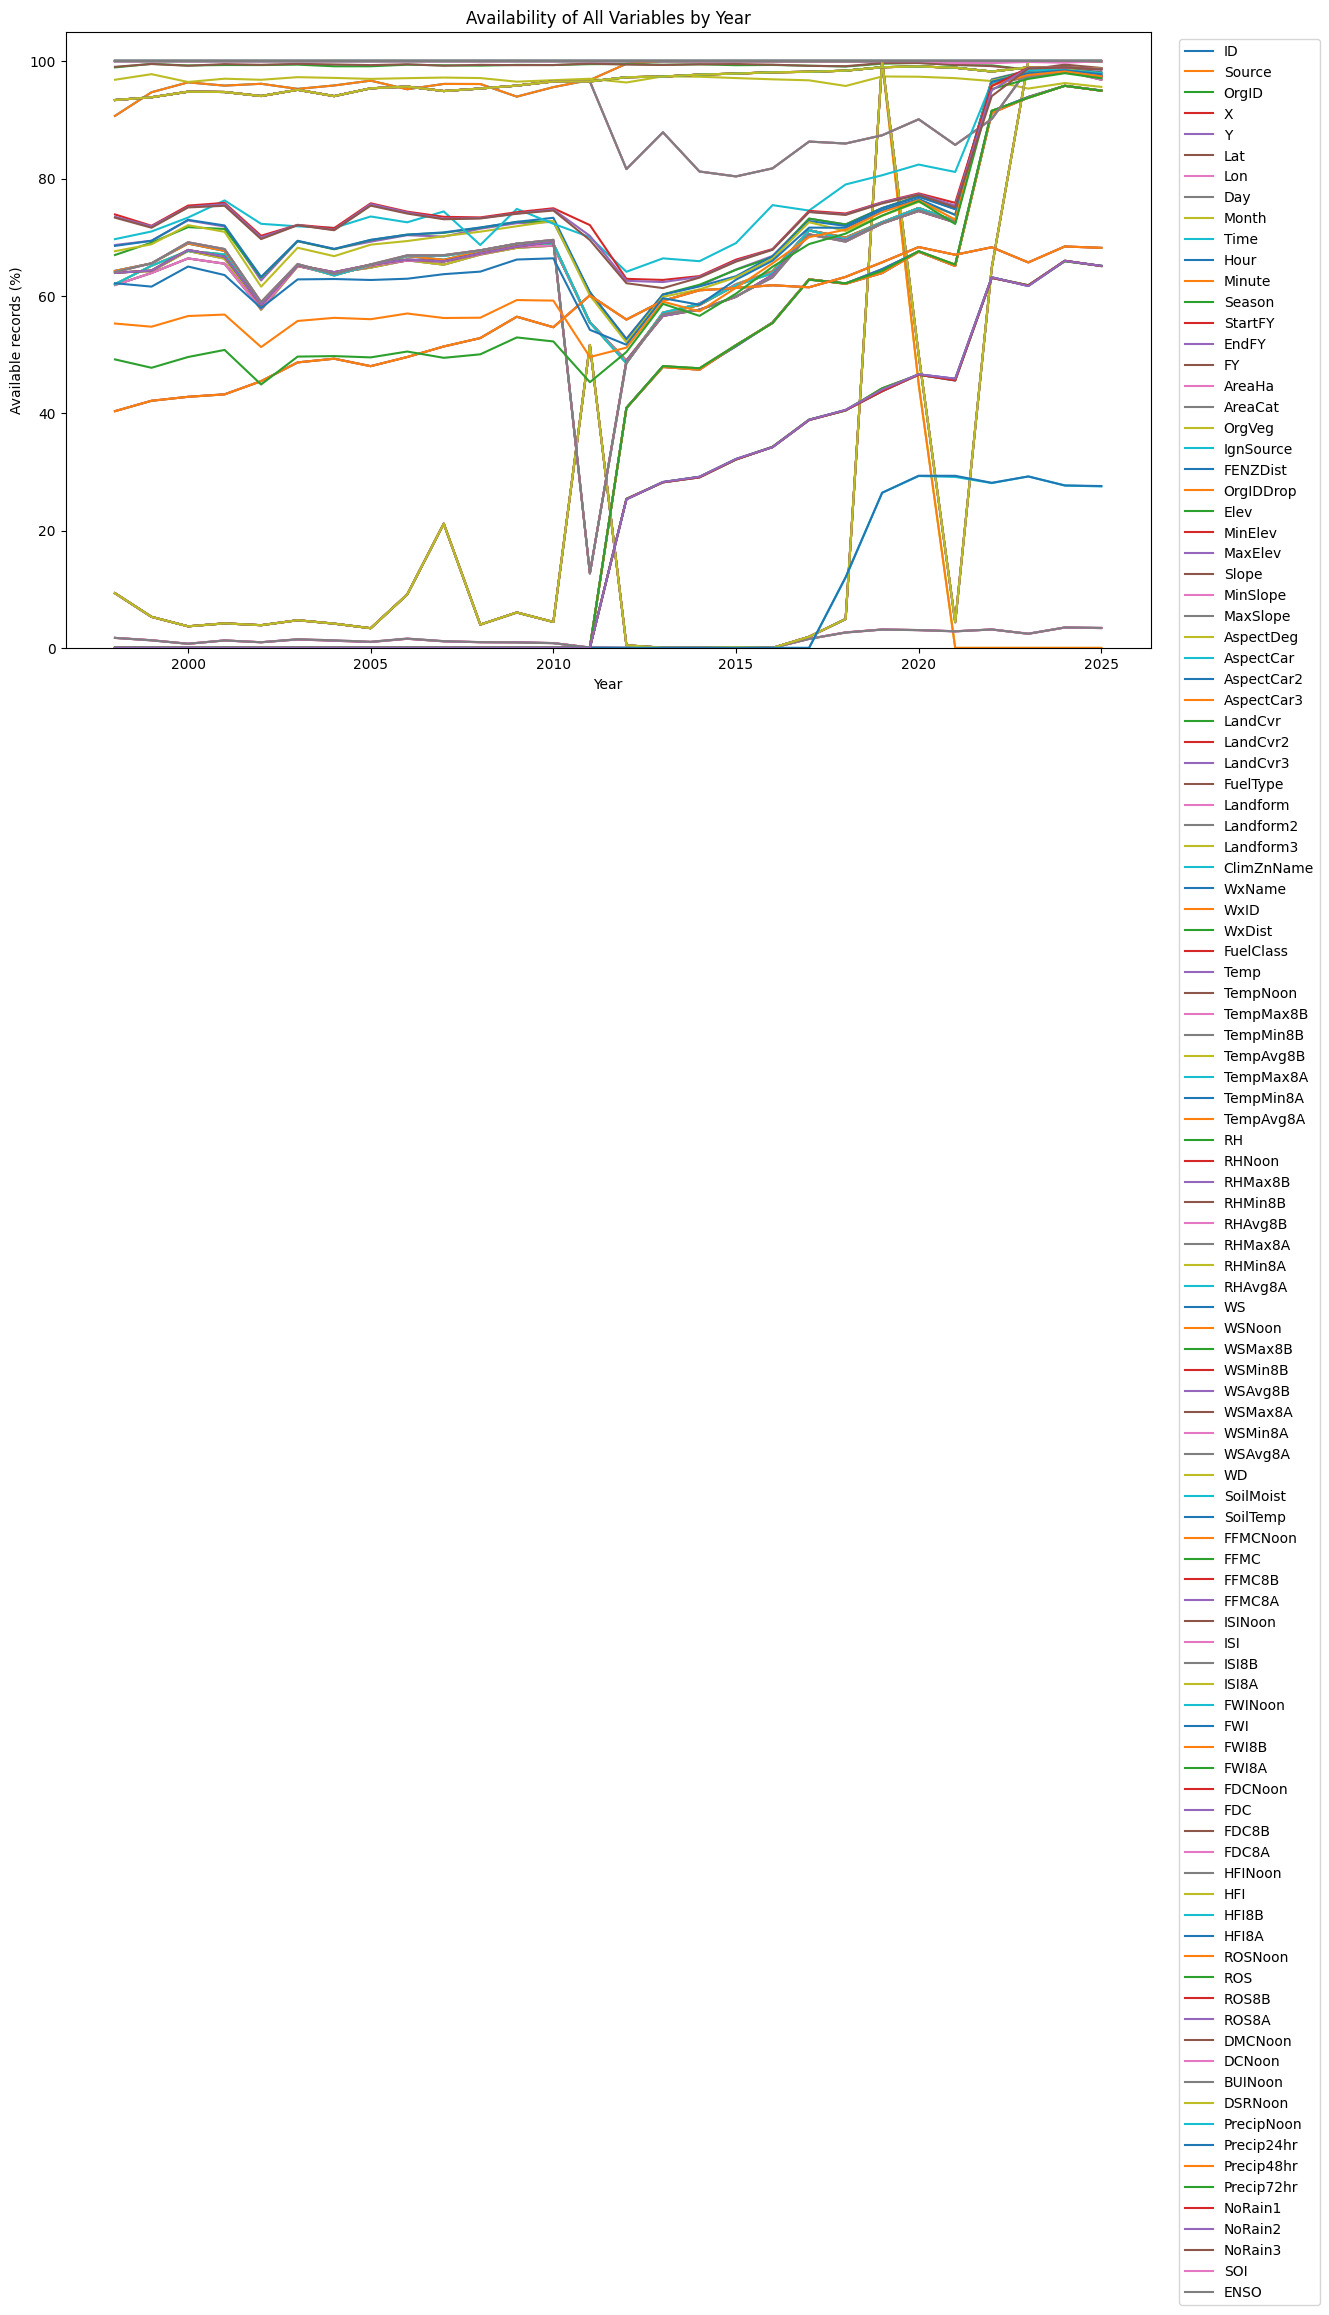

In [42]:
raw_df.replace(-9999, np.nan, inplace=True)
features = [col for col in raw_df.columns if col != "Year"]
df_filtered = raw_df[raw_df["Year"] >= 1998].copy()

# Calculate percentage of available values for each feature by year
availability = (
    df_filtered.groupby("Year")[features]
      .apply(lambda x: x.notna().mean() * 100)
)

# Plot
plt.figure(figsize=(14, 8))

for feature in features:
    plt.plot(
        availability.index,
        availability[feature],
        label=feature
    )

plt.xlabel("Year")
plt.ylabel("Available records (%)")
plt.title("Availability of All Variables by Year")

plt.ylim(0, 105)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=1
)

plt.tight_layout()
plt.show()

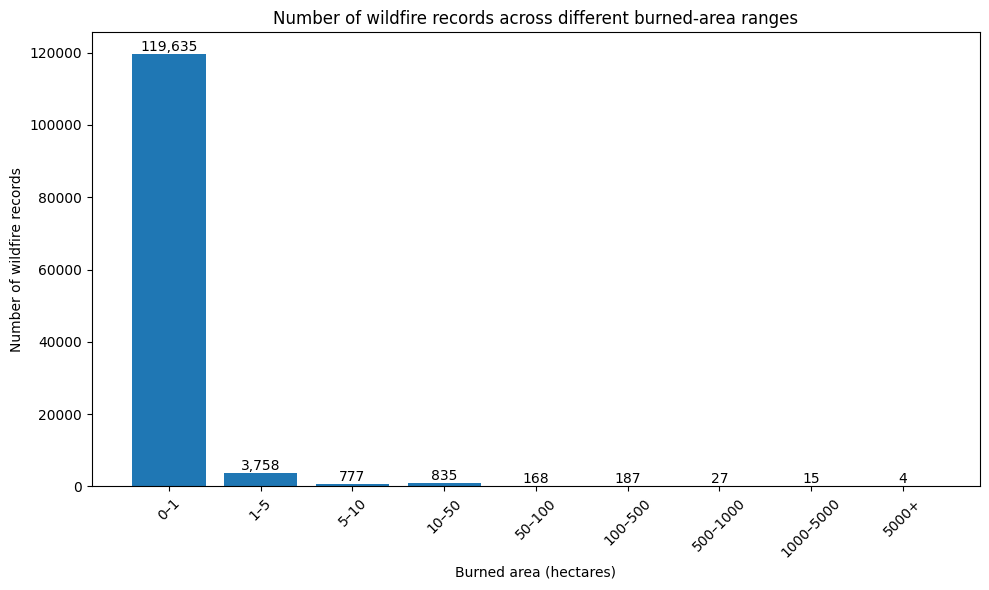

In [43]:
bins = [0, 1, 5, 10, 50, 100, 500, 1000, 5000, float("inf")]
labels = [
    "0–1",
    "1–5",
    "5–10",
    "10–50",
    "50–100",
    "100–500",
    "500–1000",
    "1000–5000",
    "5000+"
]

# Group wildfire records by burned-area range
fire_size_ranges = pd.cut(
    df["AreaHa"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
size_counts = fire_size_ranges.value_counts().sort_index()

# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(
    size_counts.index,
    size_counts.values
)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records across different burned-area ranges")

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

((array([-4.39545038, -4.19880644, -4.09192566, ...,  4.09192566,
          4.19880644,  4.39545038]),
  array([-1.0000e-04,  0.0000e+00,  0.0000e+00, ...,  5.0888e+03,
          5.6000e+03,  6.1590e+03])),
 (np.float64(3.766006620837235),
  np.float64(1.156784898342676),
  np.float64(0.09511962606561651)))

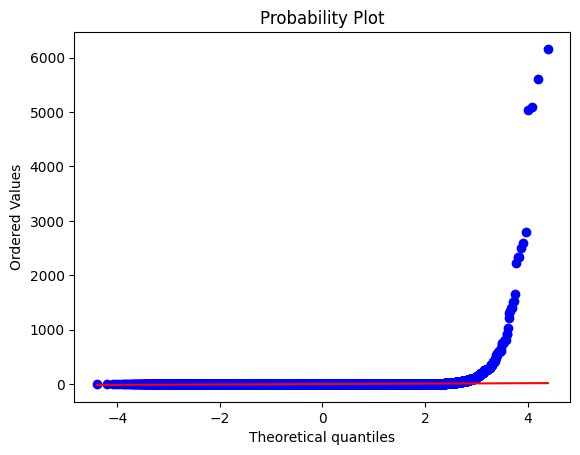

In [44]:
# sns.distplot(df["AreaHa"])

stats.probplot(df["AreaHa"], dist="norm", plot=plt)

In [45]:
df["AreaCatModified"] = np.where(
    df["AreaCat"] == "< 1",
    0,
    1
)

# 0 = Small fire (< 1 hectare)
# 1 = Large fire (>= 1 hectare)

print(df["AreaCatModified"].value_counts())

print("\nPercentage distribution:")
print(df["AreaCatModified"].value_counts(normalize=True) * 100)
df.sample(1)

AreaCatModified
0    119639
1      5768
Name: count, dtype: int64

Percentage distribution:
AreaCatModified
0   95.400576
1    4.599424
Name: proportion, dtype: float64


,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO,Period,AreaCatModified
12020,WOD12021,FENZ,A527690,1679925.000000,6087583.000000,-35.351841,173.879645,7,5,2005,...,NaN,NaN,NaN,NaN,NaN,NaN,-14.500000,El Nino,NaN,0


## Train-Test Split

In [46]:
# Ensure Year is numeric
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# Remove records with missing target or year
df = df.dropna(
    subset=["Year", "AreaCatModified"]
).copy()

# Define target
target = "AreaCatModified"

# Chronological split
train_df = df[
    df["Year"].between(1998, 2017)
].copy()

val_df = df[
    df["Year"].between(2018, 2019)
].copy()

test_df = df[
    df["Year"].between(2020, 2025)
].copy()

# Columns that must not be used as predictors
exclude_columns = [
    "AreaHa",
    "AreaCat",
    "AreaCatModified",
    "FireClass",
    "Year"
]

# Remove only columns that exist
exclude_columns = [
    col for col in exclude_columns
    if col in df.columns
]

# Prepare predictors and target
X_train = train_df.drop(columns=exclude_columns)
y_train = train_df[target]

X_val = val_df.drop(columns=exclude_columns)
y_val = val_df[target]

X_test = test_df.drop(columns=exclude_columns)
y_test = test_df[target]

## ML Pipeline for finding best Base Model

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer

### 1) Keeping Only Useful Features

In [48]:
preprocessing_features = [
    # Topographical features
    
    "AspectCar2",
    "MaxElev",
    "MinSlope",
    "AspectCar3",
    "Lat",
    "MaxSlope",
    "Elev",
    "Slope",
    "MinElev",

    # Land cover features
    "LandCvr3",
    "LandCvr2",
    "LandCvr",

    # Weather and fire-weather features
    "RH",
    "DSRNoon",
    "FWINoon",
    "ISINoon",
    "RHAvg8B",
    "RHNoon",
    "RHMin8A",

    # Location and time features
    "FENZDist",
    "Month",
    "Day",
    "Hour",

    # Added
    "Lon",
    "FuelClass",
    "FuelType"
]


trf1 = FunctionTransformer(
    lambda x: x[preprocessing_features].copy()
)

X_train_temp = trf1.fit_transform(X_train)

X_train_temp.sample(1)

,AspectCar2,MaxElev,MinSlope,AspectCar3,Lat,MaxSlope,Elev,Slope,MinElev,LandCvr3,...,RHAvg8B,RHNoon,RHMin8A,FENZDist,Month,Day,Hour,Lon,FuelClass,FuelType
7409,NaN,NaN,NaN,NaN,-38.074379,NaN,19.556639,1.000000,NaN,NaN,...,NaN,44.000000,NaN,Bay of Plenty,11,30,16.000000,177.006824,Grass,Pasture Grasslands


### 2) Replace -9999 with NAN

In [49]:
trf2 = FunctionTransformer(
    lambda X: X.replace(
        [-9999, "-9999"],
        np.nan
    ),
    validate=False
)

X_train_temp = trf2.fit_transform(X_train_temp)

X_train_temp.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AspectCar2,501,9,Southeast,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxElev,760.000000,NaN,NaN,NaN,243.387145,290.765286,0.608078,58.367142,140.415703,322.952705,1685.432617
MinSlope,767.000000,NaN,NaN,NaN,5.130378,6.269925,0.000000,0.000000,3.000000,9.000000,37.000000
AspectCar3,318,9,South,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lat,92774.000000,NaN,NaN,NaN,-40.121075,3.198826,-47.211129,-43.396778,-39.649671,-37.110931,-34.415811
MaxSlope,767.000000,NaN,NaN,NaN,13.744459,12.184285,0.000000,2.000000,12.000000,23.000000,56.000000
Elev,92161.000000,NaN,NaN,NaN,84.353800,128.222005,-1.807057,13.742782,34.333740,95.553909,2313.611572
Slope,92215.000000,NaN,NaN,NaN,2.483530,4.213611,0.000000,0.000000,1.000000,3.000000,43.000000
MinElev,760.000000,NaN,NaN,NaN,170.348295,217.049817,0.111394,20.221994,81.523914,258.060806,1460.158813
LandCvr3,139,22,High Producing Exotic Grassland,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3) Handle Missing Values

In [50]:
# Identify numerical and categorical features
numeric_cols = X_train_temp.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", numeric_cols)
print("\nCategorical features:", categorical_cols)

Numerical features: ['MaxElev', 'MinSlope', 'Lat', 'MaxSlope', 'Elev', 'Slope', 'MinElev', 'RH', 'DSRNoon', 'FWINoon', 'ISINoon', 'RHAvg8B', 'RHNoon', 'RHMin8A', 'Month', 'Day', 'Hour', 'Lon']

Categorical features: ['AspectCar2', 'AspectCar3', 'LandCvr3', 'LandCvr2', 'LandCvr', 'FENZDist', 'FuelClass', 'FuelType']


In [51]:
# Handling missing values
trf3 = ColumnTransformer(
    transformers=[
        # Handling missing values on numerical features
        (
            "trf_3_1",
            SimpleImputer(strategy="median"),
            numeric_cols
        ),

        # Handling missing values on categorical features
        (
            "trf_3_2",
            SimpleImputer(strategy="most_frequent"),
            categorical_cols
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

trf3.set_output(transform="pandas")

X_train_temp = trf3.fit_transform(X_train_temp)
X_train_temp.sample(5)

,MaxElev,MinSlope,Lat,MaxSlope,Elev,Slope,MinElev,RH,DSRNoon,FWINoon,...,Hour,Lon,AspectCar2,AspectCar3,LandCvr3,LandCvr2,LandCvr,FENZDist,FuelClass,FuelType
31988,140.415703,3.000000,-45.832340,12.000000,2.207226,5.000000,81.523914,83.000000,0.090704,1.974747,...,20.000000,170.672936,Southeast,South,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Otago,Non Fuel,Non-Fuel
57490,140.415703,3.000000,-40.363165,12.000000,31.292437,0.000000,81.523914,93.000000,0.000023,0.018418,...,18.000000,175.622923,Southeast,South,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Manawatu-Whanganui,Non Fuel,Non-Fuel
46997,140.415703,3.000000,-46.430298,12.000000,7.915417,0.000000,81.523914,74.000000,0.299936,3.881147,...,14.000000,168.302284,Southeast,South,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Southland,Non Fuel,Non-Fuel
40292,140.415703,3.000000,-43.399748,12.000000,1.729950,0.000000,81.523914,46.000000,2.283667,12.219169,...,15.000000,172.691237,Southeast,South,High Producing Exotic Grassland,High Producing Exotic Grassland,High Producing Exotic Grassland,Canterbury,Grass,Pasture Grasslands
66019,140.415703,3.000000,-37.454047,12.000000,2.415102,0.000000,81.523914,65.000000,0.006912,0.461161,...,9.000000,175.975728,Southeast,South,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Bay of Plenty,Non Fuel,Non-Fuel


### 4) Encoding Month and Hour cyclically

In [52]:
trf4 = FunctionTransformer(
    lambda X: X.assign(
        Month_sin=np.sin(2 * np.pi * (X["Month"] - 1) / 12),
        Month_cos=np.cos(2 * np.pi * (X["Month"] - 1) / 12),
        Hour_sin=np.sin(2 * np.pi * X["Hour"] / 24),
        Hour_cos=np.cos(2 * np.pi * X["Hour"] / 24)
    ).drop(columns=["Month", "Hour"]),
    validate=False
)

X_train_temp = trf4.fit_transform(X_train_temp)
X_train_temp

,MaxElev,MinSlope,Lat,MaxSlope,Elev,Slope,MinElev,RH,DSRNoon,FWINoon,...,LandCvr3,LandCvr2,LandCvr,FENZDist,FuelClass,FuelType,Month_sin,Month_cos,Hour_sin,Hour_cos
0,140.415703,3.000000,-36.830510,12.000000,80.949654,3.000000,81.523914,65.000000,0.005331,0.398246,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Auckland,Non Fuel,Non-Fuel,0.000000,-1.000000,-0.258819,0.965926
1,140.415703,3.000000,-36.857182,12.000000,17.103554,0.000000,81.523914,65.000000,0.003805,0.329166,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Auckland,Non Fuel,Non-Fuel,-0.500000,-0.866025,-0.965926,-0.258819
2,140.415703,3.000000,-35.934039,12.000000,13.878854,0.000000,81.523914,97.000000,0.000020,0.016959,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Northland,Non Fuel,Non-Fuel,-0.500000,-0.866025,-0.965926,0.258819
3,140.415703,3.000000,-36.909367,12.000000,37.544312,1.000000,81.523914,65.000000,0.010679,0.589653,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Built-up Area (settlement),Auckland,Non Fuel,Non-Fuel,-0.500000,-0.866025,0.866025,-0.500000
4,140.415703,3.000000,-37.003567,12.000000,89.214706,5.000000,81.523914,65.000000,0.010679,0.589653,...,High Producing Exotic Grassland,High Producing Exotic Grassland,High Producing Exotic Grassland,Auckland,Grass,Pasture Grasslands,-0.500000,-0.866025,0.866025,-0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103617,25.668385,0.000000,-41.762198,0.000000,23.080130,0.000000,20.012514,65.000000,0.702453,6.277219,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Exotic Forest,West Coast,Forest,Plantation Forests,-0.500000,0.866025,-0.707107,-0.707107
103618,18.546165,0.000000,-36.979490,0.000000,17.927828,0.000000,17.457582,42.000000,10.546633,29.003790,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Urban Parkland/Open Space,Auckland,Grass,Pasture Grasslands,-0.500000,0.866025,-0.258819,-0.965926
103619,226.654312,6.000000,-44.771948,11.000000,217.937174,7.148148,205.271240,62.000000,0.149670,2.620585,...,High Producing Exotic Grassland,High Producing Exotic Grassland,Low Producing Grassland,Mid-South Canterbury,Grass,Pasture Grasslands,-0.500000,0.866025,-0.500000,-0.866025
103620,83.331696,6.000000,-45.480333,11.000000,70.521182,9.227273,55.369389,80.000000,1.419801,9.341757,...,High Producing Exotic Grassland,High Producing Exotic Grassland,High Producing Exotic Grassland,Otago,Grass,Pasture Grasslands,-0.500000,0.866025,-1.000000,-0.000000


### 5) Encoding Categorical Features

In [53]:
# Identify categorical columns after trf5
categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

categorical_cols

['AspectCar2',
 'AspectCar3',
 'LandCvr3',
 'LandCvr2',
 'LandCvr',
 'FENZDist',
 'FuelClass',
 'FuelType']

In [54]:
# One-hot encoding
trf5 = ColumnTransformer(
    transformers=[
        (
            "trf_5_1",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

trf5.set_output(transform="pandas")

X_train_temp = trf5.fit_transform(X_train_temp)
X_train_temp.sample(5)

,AspectCar2_East,AspectCar2_Flat,AspectCar2_North,AspectCar2_Northeast,AspectCar2_Northwest,AspectCar2_South,AspectCar2_Southeast,AspectCar2_Southwest,AspectCar2_West,AspectCar3_East,...,ISINoon,RHAvg8B,RHNoon,RHMin8A,Day,Lon,Month_sin,Month_cos,Hour_sin,Hour_cos
64257,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,14.532000,51.750000,50.000000,68.000000,12.000000,174.784484,0.000000,1.000000,-0.965926,-0.258819
40457,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,11.807830,70.750000,47.000000,62.000000,7.000000,173.502948,0.000000,1.000000,-0.707107,-0.707107
40392,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,5.198638,71.880000,48.000000,82.000000,31.000000,172.647904,-0.500000,0.866025,0.000000,1.000000
53753,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,7.259608,70.750000,66.000000,71.000000,28.000000,175.005111,0.866025,0.500000,-0.965926,-0.258819
49605,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,4.057962,86.000000,89.000000,95.000000,27.000000,174.172032,-1.000000,-0.000000,-0.866025,-0.500000


### 6) Scaling features

In [55]:
numeric_cols = X_train_temp.select_dtypes(
    include=np.number
).columns.tolist()

trf6 = ColumnTransformer(
    transformers=[
        (
            "trf_6_1",
            StandardScaler(),
            numeric_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf6.set_output(transform="pandas")

X_train_temp = trf6.fit_transform(X_train_temp)
X_train_temp.sample(5)

,AspectCar2_East,AspectCar2_Flat,AspectCar2_North,AspectCar2_Northeast,AspectCar2_Northwest,AspectCar2_South,AspectCar2_Southeast,AspectCar2_Southwest,AspectCar2_West,AspectCar3_East,...,ISINoon,RHAvg8B,RHNoon,RHMin8A,Day,Lon,Month_sin,Month_cos,Hour_sin,Hour_cos
53994,-0.026682,-0.007341,-0.021027,-0.025650,-0.025011,-0.025860,0.067437,-0.026274,-0.026068,-0.019147,...,0.259462,0.440617,0.611746,0.093836,1.739184,0.208095,0.086428,-2.094136,-0.164732,-0.913409
8968,-0.026682,-0.007341,-0.021027,-0.025650,-0.025011,-0.025860,0.067437,-0.026274,-0.026068,-0.019147,...,-0.608629,-0.636962,-0.180890,0.027034,-0.709017,0.206789,-1.127472,0.304025,-0.799497,-0.357416
31973,-0.026682,-0.007341,-0.021027,-0.025650,-0.025011,-0.025860,0.067437,-0.026274,-0.026068,-0.019147,...,-0.661694,0.059308,-0.511155,0.027034,-0.263890,0.220171,0.787274,0.889217,-0.799497,-0.357416
74691,-0.026682,-0.007341,-0.021027,-0.025650,-0.025011,-0.025860,0.067437,-0.026274,-0.026068,-0.019147,...,-0.571832,0.069222,0.479640,0.628254,0.515083,0.347074,-1.127472,-1.294749,-0.799497,-0.357416
60633,-0.026682,-0.007341,-0.021027,-0.025650,-0.025011,-0.025860,0.067437,-0.026274,-0.026068,-0.019147,...,-0.512343,0.773881,-1.039580,-1.175408,-1.599272,-0.356910,-1.127472,0.304025,-0.523898,-0.672011


### 7) Machine Learning Model

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from xgboost import XGBClassifier


models = {
    "Logistic Regression": LogisticRegression(
        C=0.1,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        min_samples_split=10,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        min_samples_split=10,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1
    )
}

### 8) Pipeline Implementation and Model Fit

In [57]:
from sklearn.pipeline import Pipeline

pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ("trf1", trf1),
        ("trf2", trf2),
        ("trf3", trf3),
        ("trf4", trf4),
        ("trf5", trf5),
        ("trf6", trf6),
        ("model", model)
    ])

### 9) Different Models Comparisons

In [58]:
from sklearn.metrics import average_precision_score

results = []

for name, pipe in pipelines.items():

    print("Model Training Started: " + name)

    pipe.fit(X_train, y_train)

    y_val_proba = pipe.predict_proba(X_val)[:, 1]

    pr_auc = average_precision_score(y_val, y_val_proba)

    results.append({
        "Model": name,
        "PR-AUC": pr_auc
    })

    print("Model Training Completed: " + name + " with " + str(pr_auc))

Model Training Started: Logistic Regression
Model Training Completed: Logistic Regression with 0.5021517953691444
Model Training Started: Random Forest
Model Training Completed: Random Forest with 0.5331765336910629
Model Training Started: Extra Trees
Model Training Completed: Extra Trees with 0.5303591869864238
Model Training Started: Gradient Boosting
Model Training Completed: Gradient Boosting with 0.5632519955386452
Model Training Started: Hist Gradient Boosting
Model Training Completed: Hist Gradient Boosting with 0.5630921941328658
Model Training Started: XGBoost
Model Training Completed: XGBoost with 0.548976708954684


In [59]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

results_df

,Model,PR-AUC
0,Gradient Boosting,0.563252
1,Hist Gradient Boosting,0.563092
2,XGBoost,0.548977
3,Random Forest,0.533177
4,Extra Trees,0.530359
5,Logistic Regression,0.502152


### 10) Best Model Training and Evaluation

In [60]:
best_model_name = results_df.iloc[0]["Model"]

best_pipe = pipelines[best_model_name]

print("Best model:", best_model_name)

Best model: Gradient Boosting


In [64]:
# Predict probabilities for the large-fire class
y_pred_proba = best_pipe.predict_proba(X_test)[:, 1]

# Apply the selected threshold
best_threshold = 0.35
y_pred = (y_pred_proba >= best_threshold).astype(int)

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

evaluation = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_pred_proba),
    "PR-AUC": average_precision_score(y_test, y_pred_proba)
}

evaluation_df = pd.DataFrame(
    evaluation.items(),
    columns=["Metric", "Score"]
)

display(evaluation_df)

,Metric,Score
0,Accuracy,0.969681
1,Precision,0.675787
2,Recall,0.499494
3,F1-Score,0.574419
4,ROC-AUC,0.892896
5,PR-AUC,0.522045


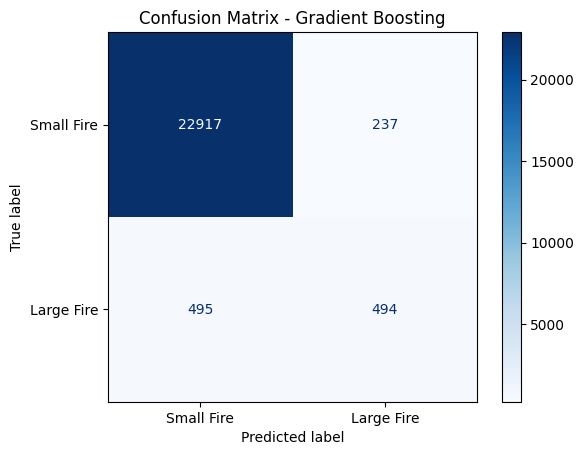

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Small Fire", "Large Fire"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [67]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Small Fire", "Large Fire"]
))

              precision    recall  f1-score   support

  Small Fire       0.98      0.99      0.98     23154
  Large Fire       0.68      0.50      0.57       989

    accuracy                           0.97     24143
   macro avg       0.83      0.74      0.78     24143
weighted avg       0.97      0.97      0.97     24143



#### - Comparison between test and train prediction

In [68]:
from sklearn.metrics import average_precision_score

# Training predictions
train_pred_proba = best_pipe.predict_proba(X_train)[:, 1]

# Validation predictions
val_pred_proba = best_pipe.predict_proba(X_val)[:, 1]

# Test predictions
test_pred_proba = best_pipe.predict_proba(X_test)[:, 1]

print(
    "Train PR-AUC:",
    average_precision_score(y_train, train_pred_proba)
)

print("Validation PR-AUC:",
      average_precision_score(y_val, val_pred_proba))

print(
    "Test PR-AUC:",
    average_precision_score(y_test, test_pred_proba)
)

Train PR-AUC: 0.3983792511388826
Validation PR-AUC: 0.5632519955386452
Test PR-AUC: 0.5220451566892418


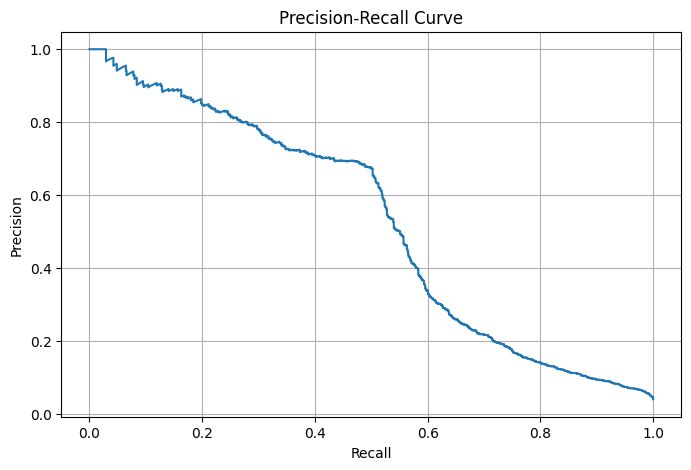

In [69]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_pred_proba
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()
plt.show()

## Classification Threshold Optimisation

In [70]:
results = []

for threshold in np.arange(0.1, 0.91, 0.05):

    y_pred = (y_pred_proba >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Accuracy  Precision   Recall  F1-Score
  0.100000  0.890800   0.225900 0.686600  0.339900
  0.150000  0.945100   0.387200 0.583400  0.465500
  0.200000  0.961300   0.526600 0.539900  0.533200
  0.250000  0.966900   0.613400 0.516700  0.560900
  0.300000  0.968700   0.653900 0.502500  0.568300
  0.350000  0.969700   0.675800 0.499500  0.574400
  0.400000  0.969800   0.684200 0.486300  0.568600
  0.450000  0.969800   0.693500 0.471200  0.561100
  0.500000  0.969200   0.694600 0.443900  0.541600
  0.550000  0.968800   0.701400 0.415600  0.521900
  0.600000  0.968600   0.717000 0.384200  0.500300
  0.650000  0.968100   0.734500 0.346800  0.471200
  0.700000  0.967800   0.769000 0.306400  0.438200
  0.750000  0.967000   0.815800 0.250800  0.383600
  0.800000  0.965200   0.867600 0.179000  0.296700
  0.850000  0.963400   0.901500 0.120300  0.212300
  0.900000  0.961100   0.946400 0.053600  0.101400


In [71]:
best_threshold = threshold_df.loc[
    threshold_df["F1-Score"].idxmax(),
    "Threshold"
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.35


In [72]:
y_pred_optimised = (
    y_pred_proba >= best_threshold
).astype(int)

In [73]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_optimised))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98     23154
           1       0.68      0.50      0.57       989

    accuracy                           0.97     24143
   macro avg       0.83      0.74      0.78     24143
weighted avg       0.97      0.97      0.97     24143



In [74]:
threshold_df[
    threshold_df["Recall"] >= 0.60
].sort_values(
    by="Precision",
    ascending=False
)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.100000,0.890776,0.225882,0.686552,0.339925


In [75]:
threshold_df[
    (threshold_df["Precision"] >= 0.60) &
    (threshold_df["Recall"] >= 0.50)
].sort_values(
    by="F1-Score",
    ascending=False
)

,Threshold,Accuracy,Precision,Recall,F1-Score
4,0.300000,0.968728,0.653947,0.502528,0.568325
3,0.250000,0.966864,0.613445,0.516684,0.560922


In [76]:
best_threshold = 0.30

y_pred_optimised = (
    y_pred_proba >= best_threshold
).astype(int)

In [77]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_optimised))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98     23154
           1       0.65      0.50      0.57       989

    accuracy                           0.97     24143
   macro avg       0.82      0.75      0.78     24143
weighted avg       0.97      0.97      0.97     24143



## Hyperparameter tuning

In [78]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

gb_model = GradientBoostingClassifier(
    random_state=42
)

pipe = Pipeline([
    ("trf1", trf1),
    ("trf2", trf2),
    ("trf3", trf3),
    ("trf4", trf4),
    ("trf5", trf5),
    ("trf6", trf6),
    ("gb_model", gb_model)
])

# Prefix parameters with gb_model__
param_grid = {
    "gb_model__n_estimators": [100, 200, 300, 400],
    "gb_model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "gb_model__max_depth": [2, 3, 4, 5],
    "gb_model__min_samples_split": [2, 5, 10, 20],
    "gb_model__min_samples_leaf": [5, 10, 20, 30],
    "gb_model__subsample": [0.7, 0.8, 0.9, 1.0],
    "gb_model__max_features": [None, "sqrt", "log2"]
}

gb_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_grid,
    n_iter=30,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


/var/folders/hz/jzgj4m6s3pgbrvk0kq1ttb6m0000gn/T/ipykernel_28964/382851220.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/var/folders/hz/jzgj4m6s3pgbrvk0kq1ttb6m0000gn/T/ipykernel_28964/382851220.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/var/folders/hz/jzgj4m6s3pgbrvk0kq1ttb6m0000gn/T/ipykernel_28964/382851220.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the futu

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('trf1',
                                              FunctionTransformer(func=<function <lambda> at 0x12a3164c0>)),
                                             ('trf2',
                                              FunctionTransformer(func=<function <lambda> at 0x12a3165e0>)),
                                             ('trf3',
                                              ColumnTransformer(transformers=[('trf_3_1',
                                                                               SimpleImputer(strategy='median'),
                                                                               ['MaxElev',
                                                                                'MinSlope',
                                                                                'Lat',
                                                                                'MaxSlope',
                                                                                'Elev',
                                                                                'Slope',
                                                                                'MinElev',
                                                                                'RH',
                                                                                'DSRNoon',
                                                                                'FW...
                   param_distributions={'gb_model__learning_rate': [0.01, 0.03,
                                                                    0.05, 0.1],
                                        'gb_model__max_depth': [2, 3, 4, 5],
                                        'gb_model__max_features': [None, 'sqrt',
                                                                   'log2'],
                                        'gb_model__min_samples_leaf': [5, 10,
                                                                       20, 30],
                                        'gb_model__min_samples_split': [2, 5,
                                                                        10,
                                                                        20],
                                        'gb_model__n_estimators': [100, 200,
                                                                   300, 400],
                                        'gb_model__subsample': [0.7, 0.8, 0.9,
                                                                1.0]},
                   random_state=42, scoring='average_precision', verbose=1)

In [79]:
print("Best Parameters:")
print(gb_search.best_params_)

print("Best CV PR-AUC:")
print(gb_search.best_score_)

Best Parameters:
{'gb_model__subsample': 0.9, 'gb_model__n_estimators': 200, 'gb_model__min_samples_split': 10, 'gb_model__min_samples_leaf': 10, 'gb_model__max_features': 'sqrt', 'gb_model__max_depth': 3, 'gb_model__learning_rate': 0.05}
Best CV PR-AUC:
nan


## Handling Class Imbalance - SMOTE

In [80]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import GradientBoostingClassifier

smote_pipe = Pipeline([
    ("trf1", trf1),
    ("trf2", trf2),
    ("trf3", trf3),
    ("trf4", trf4),
    ("trf5", trf5),
    ("trf6", trf6),

    ("smote", SMOTE(
        sampling_strategy=0.3,
        random_state=42
    )),

    ("gb_model", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

In [81]:
smote_pipe.fit(X_train, y_train)

y_val_proba = smote_pipe.predict_proba(X_val)[:, 1]

from sklearn.metrics import average_precision_score

smote_pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

print("SMOTE PR-AUC:", smote_pr_auc)

SMOTE PR-AUC: 0.4992943768008431
